In [1]:
# requires:
# conda install -c conda-forge gdal
# conda install -c conda-forge libgdal-hdf4
# conda install rasterio                      <--- needs to be the conda version; pip version has only minimal GDAL and can't open HDF files

# known problems
# Time stamp alignment is off - technically I did not correctly combine current location + next time when downloading
#     probably minor; the hourly features are so coarse; but worth fixing

import os
from functools import lru_cache
import glob
import json
import numpy as np
import pandas as pd

import rasterio
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.merge import merge
from rasterio.windows import from_bounds

import torch
from torch.utils.data import Dataset, DataLoader

In [2]:
from io import StringIO
import re

with open("sn_bound_10deg.txt") as f:
    raw = f.read()
lines = [ln for ln in raw.splitlines()
         if ln.strip() and re.match(r"^\d", ln.strip())]
buf = StringIO("\n".join(lines))
cols = ["iv", "ih", "lon_min", "lon_max", "lat_min", "lat_max"]
modis_grid = pd.read_csv(buf, delim_whitespace=True, header=None, names=cols)

def lat_lon_to_modis(ctr_lat, ctr_long):
    rows = modis_grid[ (modis_grid.lon_min <= ctr_long) & ( ctr_long <= modis_grid.lon_max) & (modis_grid.lat_min <= ctr_lat) & ( ctr_lat <= modis_grid.lat_max) ]
    return list(zip(rows.ih.values, rows.iv.values))

/tmp/ipykernel_678528/851350310.py:10: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  modis_grid = pd.read_csv(buf, delim_whitespace=True, header=None, names=cols)


In [3]:
study = '5a280544-06db-4c85-9713-842547972edd' # '338388ea-6483-472c-9cdc-c2997e645df0'

# reproduce (brittle) logic in gee_chips_v2
df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
df = df[df.set == 'train']
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df = df.dropna(subset=['timestamp'])

In [4]:
### rasterio methods ###

def _get_rasterio(path):
    with rasterio.open(path) as ds:
        arr = ds.read()
        return {
                    "array": arr,
                    "transform": ds.transform,
                    "crs": ds.crs,
                    "nodata": ds.nodata,
                    "bounds": ds.bounds,
                    "bands": ds.descriptions
                }

@lru_cache(maxsize=16)
def _get_rasterio_cached(path):
    return _get_rasterio(path)

@lru_cache(maxsize=20)
def _get_rasterio_window_cached(path, bounds):
    with rasterio.open(path) as ds:
        min_lon, min_lat, max_lon, max_lat = bounds
        window = from_bounds(min_lon, min_lat, max_lon, max_lat, ds.transform)
        return {
            "array": ds.read(window=window),
            "transform": ds.window_transform(window),
            "crs": ds.crs,
            "nodata": ds.nodata,
            "bounds": bounds, # rasterio.windows.bounds(window, ds.transform),
        }

@lru_cache(maxsize=20)
def _get_merged_rasterio_window_cached(paths, bounds_latlon):
    """Applies CRF bounds transform (to accomodate MODIS)
    """
    datasets = [rasterio.open(p) for p in paths]
    try:
        crs = datasets[0].crs
        descriptions = datasets[0].descriptions
        nodata_val = datasets[0].nodata or 255

        # transform to MODIS CRS
        left, bottom, right, top = transform_bounds(
            "EPSG:4326", # bounds assumed to come from EPSG:4326
            crs,         # but we want to use them in the target (e.g. MODIS) CRS
            *bounds_latlon,
        )

        mosaic, out_transform = merge(
            datasets,
            bounds=(left, bottom, right, top),
            nodata=nodata_val,
            resampling=rasterio.enums.Resampling.nearest,
        )
    except:
        print("Oh no! In _get_merged_rasterio_window_cached")
    finally:
        for ds in datasets:
            ds.close()

    return {
        "array": mosaic,           # (bands, H, W)
        "transform": out_transform,
        "crs": crs,
        "nodata": nodata_val,
        "bounds": (left, bottom, right, top),
        "bands": descriptions,
    }

def _reproject_all(layers):
    """Return all layers reprojected as float32."""
    ref_raster = layers[0]
    _, H_ref, W_ref = ref_raster['array'].shape
    
    aligned = [ ref_raster['array'] ]
    dst_crs = ref_raster['crs']
    dst_transform = ref_raster['transform']
    for layer in layers[1:]:
        # create new np array as destination - same channels as this layer but with target width/height
        dst = np.full((layer["array"].shape[0], H_ref, W_ref), np.nan, dtype=np.float32)
        reproject(
            source=layer["array"], # (C, H_src, W_src)
            destination=dst,
            src_transform=layer["transform"],
            src_crs=layer["crs"],
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            resampling=Resampling.nearest,   # nearest or bilinear
        )
        aligned.append(dst)

    return aligned

from rasterio.warp import reproject, calculate_default_transform
from rasterio.transform import array_bounds
from rasterio.enums import Resampling


def _reproject_all_to_meters(layers, dst_crs="EPSG:3857"):
    ref_raster = layers[0]
    _, H_ref, W_ref = ref_raster['array'].shape

    # compute transform/shape in metric CRS
    dst_transform, dst_width, dst_height = calculate_default_transform(
        ref_raster["crs"],     # source CRS (lat/lon)
        dst_crs,               # target CRS (meters)
        W_ref, H_ref,
        *ref_raster['bounds'], # in ref_raster["crs"]
    )

    aligned = []
    for layer in layers:
        C = layer["array"].shape[0]
        dst = np.full((C, dst_height, dst_width), np.nan, dtype=np.float32)

        reproject(
            source=layer["array"],
            destination=dst,
            src_transform=layer["transform"],
            src_crs=layer["crs"],
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            resampling=Resampling.nearest,
        )
        aligned.append(dst)

    return aligned, dst_transform, dst_crs


In [5]:
class ChipDataset(Dataset):
    def __init__(self,  study_id, idx_to_timestamp, chip_base_dir='chips_out', dem_base_dir='dem_out'):
        self.idx_to_timestamp = idx_to_timestamp.reset_index() # reset index to allow easy iteration but retain old index

        self.chip_dir = os.path.join(chip_base_dir, study_id)
        self.dem_dir  = os.path.join(dem_base_dir, study_id)
        self.dem_manifest = json.load(open(os.path.join(self.dem_dir, 'dem_manifest.json'), 'r'))

        self.hii_dir = '/archive/vision/beery/movebench/human_impact_index/'
        self.cvf_dir = '/archive/vision/beery/movebench/modis_cvf2015-2025/'
        self.lc_dir = '/archive/vision/beery/movebench/modis_lc2015-2025/'
        self.bioclim_dir = '/archive/vision/beery/movebench/bioclim/'

        # build modis filepath indices to avoid globs later
        # self.lc_dir + f"/MCD12Q1.A{year}001.h{h:02d}v{v:02d}*.hdf"
        self.modis_lc_index = {}
        for path in glob.glob(self.lc_dir + "/MCD12Q1.A*.h*v*.hdf"):
            fname = os.path.basename(path)
            year = int(fname.split(".A")[1][:4])
            h = int(fname.split(".h")[1][:2])
            v = int(fname.split("v")[1][:2])
            self.modis_lc_index[(int(year), int(h), int(v))] = path
        
        self.modis_cvf_index = {}
        for path in glob.glob(self.cvf_dir + "/MOD44B.A*.h*v*.hdf"):
            fname = os.path.basename(path)
            year = int(fname.split(".A")[1][:4])
            h = int(fname.split(".h")[1][:2])
            v = int(fname.split("v")[1][:2])
            self.modis_cvf_index[(int(year), int(h), int(v))] = path

        # TODO figure out where to cache these long term
        self.mean, self.std = None, None
        if os.path.exists(f'{study}_mean.pt'):
            self.mean = torch.load(f'{study}_mean.pt')
            self.std  = torch.load(f'{study}_std.pt')
        else:
            print("WARNING: Features will not be standardized for", study)

    def __getitem__(self, idx):
        idx, timestamp = self.idx_to_timestamp.iloc[idx].values # map to original df index
        idx = int(idx)
        all_layers = []
        layer_names = []
        
        # ERA5 chips
        big_chip   = _get_rasterio(os.path.join(self.chip_dir, f"point_{idx}_big.tif"))
        med_chip   = _get_rasterio(os.path.join(self.chip_dir, f"point_{idx}_medium.tif"))
        # print("big:", big_chip['array'].shape)
        # print("med:", med_chip['array'].shape)
        # right now, small is just dynamic world, and it's broken
        # small_chip = _get_rasterio(os.path.join(self.chip_dir, f"point_{idx}_small.tif"))
        all_layers.extend([med_chip, big_chip])
        layer_names.extend(["era5_med", "era5_big"]) # TODO: would need med_bands, big_bands to access these later for e.g. derived features

        # get location for other queries -- assume small will be the most accurate
        bounds = med_chip['bounds']
        center_lon = (bounds[0] + bounds[2]) / 2
        center_lat = (bounds[1] + bounds[3]) / 2

        # DEM - bigger tile
        for chunk in self.dem_manifest.get("chunk_info", []):
            b = chunk["bounds"]
            if b["min_lon"] <= center_lon <= b["max_lon"] and b["min_lat"] <= center_lat <= b["max_lat"]:
                demf = os.path.join(self.dem_dir, chunk["filename"])
                dem_raster = _get_rasterio_cached(demf)
                # dem_raster = _get_rasterio_window_cached(demf, med_chip['bounds'])
                break
        # print("DEM", dem_raster['array'].shape)
        all_layers.append(dem_raster)
        layer_names.append("DEM")
        
        # MODIS land cover -- annual, hdf files
        # int-valued (should be one-hot as features)
        year = int(max(min(timestamp.year, 2025), 2015))
        # get all files that the bounds fall into - will need to merge them
        hvs = []
        for lat in [ bounds[1], bounds[3] ]:
            for lon in [ bounds[0], bounds[2] ]:
                hvs.extend(lat_lon_to_modis(lat, lon))
        sd_paths = []
        for (h, v) in hvs:
            hdf_path_i = self.modis_lc_index[(year, int(h), int(v))]
            sd_paths.append("HDF4_EOS:EOS_GRID:" + hdf_path_i + ":MCD12Q1:LC_Type1")
        lc_raster = _get_merged_rasterio_window_cached(tuple(sd_paths), bounds)
        # print("MODIS LC", lc_raster['array'].shape)
        all_layers.append(lc_raster)
        layer_names.append("modis_lc")
        
        # MODIS vegetation cover -- annual
        cvf_rasters = []
        for band in [':MOD44B_250m_GRID:Percent_Tree_Cover', 
                     ':MOD44B_250m_GRID:Percent_NonTree_Vegetation',
                     ':MOD44B_250m_GRID:Percent_NonVegetated']:
            sd_paths = []
            for (h, v) in hvs:
                hdf_path_i = self.modis_cvf_index[(year, int(h), int(v))]
                sd_paths.append("HDF4_EOS:EOS_GRID:" + hdf_path_i + band)
            # print("merging", sd_paths)
            cvf_raster = _get_merged_rasterio_window_cached(tuple(sd_paths), bounds)
            cvf_rasters.append(cvf_raster)
        # print("MODIS CVF", [cvf_raster['array'].shape for cvf_raster in cvf_rasters])
        all_layers.extend(cvf_rasters)
        layer_names.extend(["modis_treecover", "modis_nontreeveg", "modis_nonveg"])

        # Human impact -- annual
        year = max(min(timestamp.year, 2020), 2015)
        hii_f = os.path.join(self.hii_dir, f'hii_{year}-01-01.tif')
        hii_raster = _get_rasterio_window_cached(hii_f, med_chip['bounds'])
        # print("HII", hii_raster['array'].shape)
        all_layers.append(hii_raster)
        layer_names.append("HII")

        # BioClim -- no time; whole world
        bioclim_fs = [ os.path.join(self.bioclim_dir, f"wc2.1_30s_bio_{i}.tif") for i in range(1,20) ] 
        bioclim_rasters = [ _get_rasterio_window_cached(bioclim_f, med_chip['bounds']) for bioclim_f in bioclim_fs ]
        # print("bioclim", [raster['array'].shape for raster in bioclim_rasters])
        all_layers.extend(bioclim_rasters)
        layer_names.extend([ f"bioclim_{i}" for i in range(1,20) ])

        # reproject all to same resolution/CRS/bounds
        # and convert to torch
        # TODO project to meters, not lat/long
        # reprojected = _reproject_all(all_layers)
        reprojected, final_transform, final_crs = _reproject_all_to_meters(all_layers)
        reprojected_t =[
            torch.from_numpy(l) for l in reprojected
        ]

        # TODO add derived types - e.g. uplift
        # ...later...

        # convert classification data to one-hot
        lc_idx = layer_names.index("modis_lc")
        lc_nc  = 18 # should be 17 classes in modis land cover, but sometimes there are 0 vals
        reprojected_t[lc_idx][reprojected_t[lc_idx] > 17] = 0 # make any invalid entries 0
        reprojected_t[lc_idx] = torch.nn.functional.one_hot(reprojected_t[lc_idx].long(), 
                                                            num_classes=lc_nc).squeeze(0).permute(2,0,1)
        
        # compute the nodata mask
        nodata_vals  = [ a['nodata'] or torch.inf for a in all_layers ] # need to 'or' to catch None values, which mess up the equality test
        valid_masks  = [ (layer != nodata_val) for layer, nodata_val in zip(reprojected_t, nodata_vals) ]

        # concat and standardize columns if appropriate
        final_t = torch.cat(reprojected_t)
        lc_start_idx = sum([ a['array'].shape[0] for a in all_layers[:lc_idx] ])
        if self.mean is not None:
            norm_mask = torch.ones(final_t.shape[0], dtype=bool)
            norm_mask[lc_start_idx:lc_start_idx+lc_nc] = False
            normed = (final_t - self.mean[:, None, None]) / self.std[:, None, None]
            final_t = torch.where(norm_mask[:, None, None], normed, final_t)

        return final_t, torch.cat(valid_masks), final_transform, final_crs

    def __len__(self):
        return len(self.idx_to_timestamp)

In [6]:
# import time
ds = ChipDataset(study, idx_to_timestamp=pd.to_datetime(df.timestamp))
ds[393][0]

tensor([[[-8.3843e-01, -8.3843e-01, -8.3843e-01,  ..., -7.4757e-01,
          -7.4757e-01,        -inf],
         [-1.4432e+00, -1.4432e+00, -1.4432e+00,  ...,        -inf,
                 -inf,        -inf],
         [-1.4432e+00, -1.4432e+00, -1.4432e+00,  ...,        -inf,
                 -inf,        -inf],
         ...,
         [       -inf,        -inf,        -inf,  ...,  5.8403e-01,
           2.4918e-01,  2.4918e-01],
         [       -inf,        -inf,        -inf,  ...,  5.8403e-01,
           2.4918e-01,  2.4918e-01],
         [       -inf,        -inf,        -inf,  ...,  5.8403e-01,
           5.8403e-01,  5.8403e-01]],

        [[-3.2679e-01, -3.2679e-01, -3.2679e-01,  ..., -8.1800e-01,
          -8.1800e-01,        -inf],
         [-2.7483e-01, -2.7483e-01, -2.7483e-01,  ...,        -inf,
                 -inf,        -inf],
         [-2.7483e-01, -2.7483e-01, -2.7483e-01,  ...,        -inf,
                 -inf,        -inf],
         ...,
         [-1.3785e-01, -1

------

Standardization

In [ ]:
## Standardization ##
## TODO: Subsample ~1000 randomly per study ##
from tqdm import tqdm

studies = [ d for d in os.listdir('dem_out') if os.path.isdir('dem_out/'+d) ]
studies.remove('c73c7698-2c6b-44d4-8879-fe10d7536935') # this one failed

for study in studies:
    if os.path.exists(f'{study}_mean.pt'):
        print("Already computed", study)
    else:
        print("Getting standardization values for", study)

        df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
        df = df[df.set == 'train']
        df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
        df = df.dropna(subset=['timestamp'])
        
        ds = ChipDataset(study, idx_to_timestamp=pd.to_datetime(df.timestamp))
        dataloader = DataLoader(ds, 
                        batch_size=1,
                        shuffle=True,
                        num_workers=16)

        # get values for standardization
        layer_sum = None
        layer_sq_sum = None
        count = None
        num_to_sample = 1000
        for i_batch, (x, valid_mask, _, _) in tqdm(enumerate(dataloader), total=num_to_sample):
            x = x.squeeze(0)
            valid_mask = valid_mask.squeeze(0)
            num_valid  = valid_mask.sum(dim=(-1, -2))  # (C,)
            x_clean = torch.where(valid_mask, x, torch.zeros_like(x))

            # Per-layer sums
            s  = x_clean.sum(dim=(-1, -2))         # (C,)
            s2 = (x_clean ** 2).sum(dim=(-1, -2))  # (C,)

            if layer_sum is None:
                layer_sum = s
                layer_sq_sum = s2
                count = num_valid
            else:
                layer_sum += s
                layer_sq_sum += s2
                count += num_valid

            # just sample 1000 chips max
            if i_batch >= num_to_sample: 
                break

        print("Done")

        mean = layer_sum / count
        var  = layer_sq_sum / count - mean**2
        var = torch.clamp(var, min=0.0)
        std = torch.sqrt(var)

        torch.save(mean, f'{study}_mean.pt')
        torch.save(std,  f'{study}_std.pt')

        print("Saved", study)

----

SSF

In [13]:
from shapely import Point
import numpy as np
import math
from pyproj import Transformer
import pandas as pd
import glob

# def setup_df_for_ssf(df, step_multiplier=2, step_q=0.95):
#     df = df.copy()
#     df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
#     df = df.dropna(subset=['timestamp'])

#     # filter anomalous time gaps
#     df = df.sort_values(['individual-local-identifier', "timestamp"])
#     df['time_since_last'] = df.groupby('individual-local-identifier')["timestamp"].diff()
#     gap_q = 0.999  # very high quantile for time gap per individual
#     per_indiv_cutoff = (
#         df.groupby('individual-local-identifier')['time_since_last']
#         .transform(lambda s: s.dropna().quantile(gap_q))
#     )
#     data = df[
#         df['time_since_last'].notna() &
#         (df['time_since_last'] <= per_indiv_cutoff)
#     ].copy()

#     # add step length
#     R = 6371000.0  # Earth radius in meters
#     lat = np.deg2rad(data["location-lat"].to_numpy())
#     lon = np.deg2rad(data["location-long"].to_numpy())
#     lat1, lat2 = lat[:-1], lat[1:]
#     lon1, lon2 = lon[:-1], lon[1:]
#     dlat = lat2 - lat1
#     dlon = lon2 - lon1
#     a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
#     c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
#     step_length = R * c  # shape (N-1,)
#     data.loc[data.index[1:], "step_length_m"] = step_length

#     # add turn angles
#     y = np.sin(dlon) * np.cos(lat2)
#     x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
#     bearing = np.arctan2(y, x)  # shape (N-1,), range [-pi, pi]
#     data.loc[data.index[1:], "bearing"] = bearing
#     turn = np.diff(bearing)     # (N-2,)
#     # wrap into [-pi, pi] to avoid jumps near the ±pi boundary
#     turn = (turn + np.pi) % (2.0 * np.pi) - np.pi
#     data.loc[data.index[2:], "turn_angle_rad"] = turn

#     # filter by step length
#     max_step_len = step_multiplier * np.nanquantile(data['step_length_m'].values, q=step_q)
#     data = data[ (data['step_length_m'] <= max_step_len) & (data['step_length_m'] > 0) ]

#     return data.reset_index()

# def setup_df_for_ssf(df, step_multiplier=2, step_q=0.95, gap_q=0.999):
#     df = df.copy()
#     df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
#     df = df.dropna(subset=['timestamp'])

#     # sort so diffs make sense
#     df = df.sort_values(['individual-local-identifier', 'timestamp'])
    
#     df['lat_rad'] = np.deg2rad(df['location-lat'])
#     df['lon_rad'] = np.deg2rad(df['location-long'])
    
#     g = df.groupby('individual-local-identifier')

#     # filter time gaps per individual 
#     df['time_since_last'] = g['timestamp'].diff()
#     per_indiv_cutoff = g['time_since_last'].transform(
#         lambda s: s.dropna().quantile(gap_q)
#     )
#     df['within_time'] = df['time_since_last'] <= per_indiv_cutoff

#     # step length per individual
#     R = 6371000.0  # Earth radius in meters
#     df['lat_prev'] = g['lat_rad'].shift()
#     df['lon_prev'] = g['lon_rad'].shift()
#     dlat = df['lat_rad'] - df['lat_prev']
#     dlon = df['lon_rad'] - df['lon_prev']
#     a = np.sin(dlat / 2.0) ** 2 + np.cos(df['lat_prev']) * np.cos(df['lat_rad']) * np.sin(dlon / 2.0) ** 2
#     c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
#     df['step_length_m'] = R * c
#     # initial valid step mask (time + positive distance)
#     df['valid_step'] = (
#         df['within_time'] &
#         df['step_length_m'].notna() &
#         (df['step_length_m'] > 0)
#     )

#     # step-length cutoff
#     max_step_len = step_multiplier * np.nanquantile(
#         df.loc[df['valid_step'], 'step_length_m'], q=step_q
#     )
#     df['max_step_len'] = max_step_len  # optional, for debugging
#     df['valid_step'] &= df['step_length_m'] <= max_step_len

#     # turn angles for valid steps
#     y = np.sin(dlon) * np.cos(df['lat_rad'])
#     x = (
#         np.cos(df['lat_prev']) * np.sin(df['lat_rad']) -
#         np.sin(df['lat_prev']) * np.cos(df['lat_rad']) * np.cos(dlon)
#     )
#     df['bearing'] = np.arctan2(y, x)  # [-pi, pi], NaN at first row per individual
#     df['bearing_prev'] = g['bearing'].shift()
#     df['valid_step_prev'] = g['valid_step'].shift()
#     turn = df['bearing'] - df['bearing_prev']
#     # wrap into [-pi, pi] to avoid jumps near ±pi
#     turn = (turn + np.pi) % (2.0 * np.pi) - np.pi
#     df['turn_angle_rad'] = np.where(
#         df['valid_step'] & df['valid_step_prev'],
#         turn,
#         np.nan
#     )

#     # finally, compute bursts within each individual
#     # burst boundary at:
#     #   - first row of each individual (valid_step is NaN), or
#     #   - current step is invalid (valid_step is False)
#     df['burst_start'] = df['valid_step'].isna() | (~df['valid_step'])
#     df['burst_id'] = g['burst_start'].cumsum()

#     # optional - drop helpers
#     # df = df.drop(columns=['lat_rad', 'lon_rad', 'lat_prev', 'lon_prev',
#                         #   'bearing_prev', 'burst_start'])

#     return df.reset_index()

def setup_df_for_ssf(df, step_multiplier=2, step_q=0.95, gap_q=0.999):
    df = df.copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    df = df.dropna(subset=['timestamp'])

    # sort so diffs make sense; keep original index (chip ids)
    df = df.sort_values(['individual-local-identifier', 'timestamp'])

    df['lat_rad'] = np.deg2rad(df['location-lat'])
    df['lon_rad'] = np.deg2rad(df['location-long'])
    
    g = df.groupby('individual-local-identifier')

    # ---- time gaps per individual ----
    df['time_since_last'] = g['timestamp'].diff()
    per_indiv_cutoff = g['time_since_last'].transform(
        lambda s: s.dropna().quantile(gap_q)
    )
    df['within_time'] = df['time_since_last'] <= per_indiv_cutoff

    # ---- step length per individual ----
    R = 6371000.0  # Earth radius in meters
    df['lat_prev'] = g['lat_rad'].shift()
    df['lon_prev'] = g['lon_rad'].shift()
    dlat = df['lat_rad'] - df['lat_prev']
    dlon = df['lon_rad'] - df['lon_prev']

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(df['lat_prev']) * np.cos(df['lat_rad']) * np.sin(dlon / 2.0) ** 2
    )
    c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))
    df['step_length_m'] = R * c

    # initial valid step mask (time + positive distance)
    df['valid_step'] = (
        df['within_time']
        & df['step_length_m'].notna()
        & (df['step_length_m'] > 0)
    )

    # ---- step-length cutoff ----
    max_step_len = step_multiplier * np.nanquantile(
        df.loc[df['valid_step'], 'step_length_m'], q=step_q
    )
    df['max_step_len'] = max_step_len  # optional
    df['valid_step'] &= df['step_length_m'] <= max_step_len

    # ---- turn angles ----
    y = np.sin(dlon) * np.cos(df['lat_rad'])
    x = (
        np.cos(df['lat_prev']) * np.sin(df['lat_rad'])
        - np.sin(df['lat_prev']) * np.cos(df['lat_rad']) * np.cos(dlon)
    )
    df['bearing'] = np.arctan2(y, x)  # [-pi, pi], NaN at first row per individual

    df['bearing_prev'] = g['bearing'].shift()
    df['valid_step_prev'] = g['valid_step'].shift()

    turn = df['bearing'] - df['bearing_prev']
    turn = (turn + np.pi) % (2.0 * np.pi) - np.pi  # wrap

    df['turn_angle_rad'] = np.where(
        df['valid_step'] & df['valid_step_prev'],
        turn,
        np.nan,
    )

    # ---- bursts ----
    df['is_first_in_indiv'] = g.cumcount() == 0
    df['burst_start'] = df['is_first_in_indiv'] | (~df['valid_step'])
    df['burst_id'] = g['burst_start'].cumsum()

    # ---- SSF sample starts ----
    # index of the next row in time order
    df['next_index'] = df.index.to_series().shift(-1).astype('Int64')

    same_indiv_next = df['individual-local-identifier'].eq(
        df['individual-local-identifier'].shift(-1)
    )
    same_burst_next = df['burst_id'].eq(df['burst_id'].shift(-1))
    valid_step_next = df['valid_step'].shift(-1).fillna(False)  # step from current -> next

    df['can_be_ssf_start'] = (
        ~df['is_first_in_indiv'] &
        same_indiv_next &
        same_burst_next &
        valid_step_next
    )

    # optional - drop helpers you don't care about downstream
    df = df.drop(
        columns=[
            'lat_rad',
            'lon_rad',
            'lat_prev',
            'lon_prev',
            'bearing_prev',
            'burst_start',
            'is_first_in_indiv',
        ]
    )

    return df


In [14]:
df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
df = df[df.set == 'train']

df = setup_df_for_ssf(df)
df.head()

/tmp/ipykernel_678528/345172576.py:210: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df['valid_step'].shift(-1).fillna(False)  # step from current -> next


,Unnamed: 0,event-id,visible,timestamp,location-long,location-lat,gps:fix-type,gps:fix-type-raw,gps:hdop,gps:satellite-count,...,within_time,step_length_m,valid_step,max_step_len,bearing,valid_step_prev,turn_angle_rad,burst_id,next_index,can_be_ssf_start
0,0,29538063317,True,2019-04-10 00:00:00,-92.823760,57.877814,2,Resolved QFP,1.5,9,...,False,NaN,False,6357.680811,NaN,NaN,NaN,1,1,False
1,1,29538063318,True,2019-04-10 01:30:00,-92.824403,57.877886,2,Resolved QFP,6.1,6,...,True,38.851370,True,6357.680811,-1.363236,False,NaN,1,2,True
2,2,29538063319,True,2019-04-10 03:00:00,-92.859990,57.887560,2,Resolved QFP,1.5,7,...,True,2362.863555,True,6357.680811,-1.097877,True,0.265359,1,3,True
3,3,29538063320,True,2019-04-10 04:30:00,-92.885635,57.887463,2,Resolved QFP,1.1,8,...,True,1515.897800,True,6357.680811,-1.577722,True,-0.479845,1,4,True
4,4,29538063321,True,2019-04-10 06:00:00,-92.885662,57.887452,2,Resolved QFP,1.1,8,...,True,2.010760,True,6357.680811,-2.224713,True,-0.646991,1,5,True


In [44]:
from rasterio.transform import array_bounds


class SSFDataset(ChipDataset):
    def __init__(self,  
                 study_id, 
                 df, 
                 random_seed: int = 0,
                 num_candidates: int = 100,
                 filter_quantile: float = 0.98, # TODO
                 chip_base_dir='chips_out', 
                 dem_base_dir='dem_out'):
        """Assume df is already filtered to train or test"""

        self.df = setup_df_for_ssf(df.copy())
        # super().__init__(study_id, idx_to_timestamp=pd.to_datetime(self.df.timestamp), chip_base_dir=chip_base_dir, dem_base_dir=dem_base_dir)
        self.sample_indices = self.df.index[self.df['can_be_ssf_start']].to_numpy()
        timestamps = pd.to_datetime(self.df.loc[self.sample_indices, 'timestamp'])
        super().__init__(
            study_id,
            idx_to_timestamp=timestamps,
            chip_base_dir=chip_base_dir,
            dem_base_dir=dem_base_dir,
        )

        self.random_seed = random_seed
        self.rng = np.random.default_rng(self.random_seed)
        self.num_candidates = num_candidates
        self.filter_quantile = filter_quantile
        self.valid_lengths = None
        self.valid_turns = None
        self._sl_scale = None
        self._log_sl_mean = None
        self._log_sl_std = None

    # def __getitem__(self, idx):
    #     chip, valid_mask, chip_transform, chip_crs = super().__getitem__(idx)
    #     C, H, W = chip.shape

    #     row = self.df.iloc[idx]
    #     start_lat = row['location-lat']
    #     start_long = row['location-long']
    #     start_bearing = row['bearing']
    #     steps_m, turns_rad = self._get_pseudo_steps_and_turns(self.num_candidates, self.rng)
        
    #     # start point -> pixel on chip
    #     transformer = Transformer.from_crs("EPSG:4326", chip_crs, always_xy=True)
    #     x0, y0 = transformer.transform(start_long, start_lat)  # note (lon, lat) order
        
    #     # get psuedo end points
    #     steps_m = np.asarray(steps_m, dtype=float)      # shape (N,)
    #     turns_rad = np.asarray(turns_rad, dtype=float)  # shape (N,)
    #     headings = start_bearing + turns_rad            # (N,)
    #     # wrap to [-pi, pi]
    #     headings = (headings + np.pi) % (2 * np.pi) - np.pi
    #     dx = steps_m * np.sin(headings)  # east-west
    #     dy = steps_m * np.cos(headings)  # north-south
    #     xs = x0 + dx   # (N,)
    #     ys = y0 + dy   # (N,)

    #     # TODO append true x,y
    #     # TODO this should come from super class method - we'll need it there too
    #     # - this is probably going to be buggy
    #     # - maybe should add in the 'burst' thing that people do
    #     next_row = self.df.iloc[idx+1]
    #     end_lat = next_row['location-lat']
    #     end_long = next_row['location-long']
    #     x1, y1 = transformer.transform(end_long, end_lat)
    #     xs = np.append(xs, x1)
    #     ys = np.append(ys, y1)
        
    #     # get features at (x,y) locations
    #     # TODO change to bilinear interp
    #     rows, cols = rasterio.transform.rowcol(chip_transform, xs, ys)
    #     rows = np.asarray(rows)
    #     cols = np.asarray(cols)

    #     H, W = chip.shape[1:]
    #     valid = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
    #     rows_valid = rows[valid]
    #     cols_valid = cols[valid]
    #     step_pixels = chip[:, rows_valid, cols_valid]
    #     valid_pixels = valid_mask[:, rows_valid, cols_valid]

    #     return step_pixels, valid_pixels, chip_transform, chip_crs  # steps_m, turns_m, ground truth y?

    def __getitem__(self, idx):
        # get chip and spatial info from parent
        chip, valid_mask, chip_transform, chip_crs = super().__getitem__(idx)
        C, H, W = chip.shape

        # map dataset idx -> (original df index, timestamp)
        orig_idx, timestamp = self.idx_to_timestamp.iloc[idx].values
        orig_idx = int(orig_idx)

        # start location
        row = self.df.loc[orig_idx]
        start_lat = row['location-lat']
        start_long = row['location-long']
        start_bearing = row['bearing']

        # sample candidate steps (pseudo-negatives)
        steps_m, turns_rad = self._get_pseudo_steps_and_turns(
            self.num_candidates, self.rng
        )
        print("steps", steps_m)
        print("turns", turns_rad)
        transformer = Transformer.from_crs("EPSG:4326", chip_crs, always_xy=True)
        x0, y0 = transformer.transform(start_long, start_lat)
        steps_m = np.asarray(steps_m, dtype=float)
        turns_rad = np.asarray(turns_rad, dtype=float)
        headings = start_bearing + turns_rad
        headings = (headings + np.pi) % (2 * np.pi) - np.pi # wrap to [-pi, pi]
        dx = steps_m * np.sin(headings)
        dy = steps_m * np.cos(headings)
        xs = x0 + dx
        ys = y0 + dy

        # append true endpoint
        next_idx = int(row['next_index'])
        next_row = self.df.loc[next_idx]
        end_lat = next_row['location-lat']
        end_long = next_row['location-long']
        x1, y1 = transformer.transform(end_long, end_lat)
        xs = np.append(xs, x1)
        ys = np.append(ys, y1)

        # get features at (x,y) locations
        # TODO change to bilinear interp
        rows, cols = rasterio.transform.rowcol(chip_transform, xs, ys)
        rows = np.asarray(rows)
        cols = np.asarray(cols)

        H, W = chip.shape[1:]
        valid = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
        rows_valid = rows[valid]
        cols_valid = cols[valid]
        print("invalid rows/cols", rows[~valid], cols[~valid])

        step_pixels = chip[:, rows_valid, cols_valid]
        valid_pixels = valid_mask[:, rows_valid, cols_valid]

        return step_pixels, valid_pixels, chip_transform, chip_crs

    def _get_pseudo_steps_and_turns(self, total_random_samples: int, rng: np.random.Generator):
        """Sample pseudo step lengths and turn angles. Override in subclasses."""
        valid_lengths = self.df.loc[self.df['valid_step'], 'step_length_m']
        valid_turns   = self.df['turn_angle_rad'][~np.isnan(self.df['turn_angle_rad'])]
        pseudo_lens = rng.choice(valid_lengths, size=total_random_samples, replace=True) if total_random_samples > 0 else np.array([])
        pseudo_turns = rng.choice(valid_turns, size=total_random_samples, replace=True) if total_random_samples > 0 else np.array([])
        return pseudo_lens, pseudo_turns
    
    def __len__(self):
        return len(self.sample_indices)

from scipy import stats

class iSSFDataset(SSFDataset):
    """
    Integrated SSF dataset with parametric movement distributions
    and movement-environment interaction features.
    """
    def _get_pseudo_steps_and_turns(self, total_random_samples: int, rng: np.random.Generator):
        """Sample from fitted gamma (step) and von Mises (turn) distributions."""
        pseudo_lens, pseudo_turns = super()._get_pseudo_steps_and_turns(total_random_samples, rng)
        valid_lengths = self.df['step_length_m']
        valid_turns   = self.df['turn_angle_rad'][~np.isnan(self.df['turn_angle_rad'])]

        try:
            self.gamma_params = stats.gamma.fit(valid_lengths, floc=0)
            pseudo_lens = stats.gamma.rvs(*self.gamma_params, size=total_random_samples, random_state=rng)
        except:
            print("Gamma fit failed, using empirical distribution.")

        try:
            self.vonmises_params = stats.vonmises.fit(valid_turns)
            pseudo_turns = stats.vonmises.rvs(*self.vonmises_params, size=total_random_samples, random_state=rng)
        except:
            print("Von Mises fit failed, using empirical distribution.")

        return pseudo_lens, pseudo_turns

In [45]:
df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
df = df[df.set == 'train']
sds = SSFDataset(study, df)

/tmp/ipykernel_678528/345172576.py:210: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid_step_next = df['valid_step'].shift(-1).fillna(False)  # step from current -> next


In [46]:
step_pixels, valid_pixels, chip_transform, chip_crs = sds[0]
step_pixels.shape, valid_pixels.shape

steps [5.53140546e+02 3.15402255e+01 4.13266975e+03 8.35832427e+02
 3.96980712e+03 1.06329234e+01 4.15177652e+02 1.50572610e+01
 1.28037683e+03 9.45975763e+00 9.33927105e+00 9.98132343e+02
 2.88652558e+02 5.02925352e+02 3.74205812e+03 6.55382534e+02
 4.88316327e+02 2.47791628e+03 1.50968137e+01 6.44261463e+00
 1.51585606e+01 4.12917731e+03 3.83372592e+00 3.85835196e+00
 1.03855536e+01 7.70097081e+00 2.54432818e+03 1.08468149e+03
 6.36572775e+02 6.55382534e+02 1.81759004e+01 2.04117948e+03
 5.67756543e+00 7.27863660e+02 2.65727412e+02 2.37415313e+01
 9.60074176e+00 1.14579584e+02 2.40736144e+03 7.27132600e+00
 5.36155779e+00 3.10522494e+02 9.75967922e+00 9.70936096e+00
 1.02074206e+01 1.47574071e+02 7.45216030e+00 1.00977748e+01
 1.01067346e+03 1.15150132e+01 5.62947498e+02 3.41010726e+02
 2.30414044e+03 1.63310621e+03 2.34334137e+03 1.28189378e+03
 4.79731471e+02 1.11722895e+03 2.23220814e+03 1.19328619e+01
 7.02484739e+02 2.78968837e+03 3.52352480e+00 1.27699325e+03
 8.28630182e+00 1.

(torch.Size([63, 101]), torch.Size([63, 101]))

In [20]:
rng = np.random.default_rng(0)
steps,turns = sds._get_pseudo_steps_and_turns(100, rng)

(array([24., 11.,  8.,  4., 13., 10.,  7.,  6.,  6., 11.]),
 array([-3.13175202e+00, -2.50490612e+00, -1.87806021e+00, -1.25121431e+00,
        -6.24368403e-01,  2.47750106e-03,  6.29323405e-01,  1.25616931e+00,
         1.88301521e+00,  2.50986112e+00,  3.13670702e+00]),
 <BarContainer object of 10 artists>)

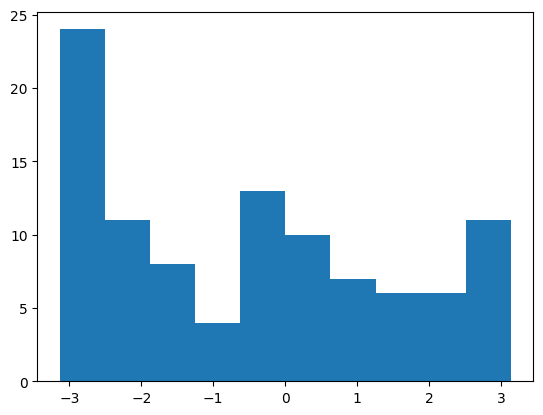

In [21]:
import matplotlib.pyplot as plt

plt.hist(turns)

----

Compute and cache features


In [13]:
from tqdm import tqdm

studies = [ d for d in os.listdir('dem_out') if os.path.isdir('dem_out/'+d) ]
studies.remove('c73c7698-2c6b-44d4-8879-fe10d7536935') # this one failed

for study in studies:
    if os.path.exists(f'{study}_ssf_features.pt'):
        print("Already computed SSF features for", study)
    else:
        print("Getting SSF features values for", study)

        df = pd.read_csv(glob.glob(f'mbr_studies_2year_filtered_traintest/{study}*')[0])
        df = df[df.set == 'train']
        df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
        df = df.dropna(subset=['timestamp'])
    
        sds = SSFDataset(study, df)

        dataloader = DataLoader(sds, 
                        batch_size=1,
                        shuffle=True,
                        num_workers=64)

        # get values for standardization
        xs = None
        xs_valid = None
        ys = None
        for i_batch, (step_pixels, valid_pixels, _, _) in tqdm(enumerate(dataloader), total=len(sds)):
            print(step_pixels.shape)
            
        break
    break
        #     x = x.squeeze(0)
        #     valid_mask = valid_mask.squeeze(0)
        #     num_valid  = valid_mask.sum(dim=(-1, -2))  # (C,)
        #     x_clean = torch.where(valid_mask, x, torch.zeros_like(x))

        #     # Per-layer sums
        #     s  = x_clean.sum(dim=(-1, -2))         # (C,)
        #     s2 = (x_clean ** 2).sum(dim=(-1, -2))  # (C,)

        #     if layer_sum is None:
        #         layer_sum = s
        #         layer_sq_sum = s2
        #         count = num_valid
        #     else:
        #         layer_sum += s
        #         layer_sq_sum += s2
        #         count += num_valid

        #     # just sample 1000 chips max
        #     if i_batch >= num_to_sample: 
        #         break

        # print("Done")

        # mean = layer_sum / count
        # var  = layer_sq_sum / count - mean**2
        # var = torch.clamp(var, min=0.0)
        # std = torch.sqrt(var)

        # torch.save(mean, f'{study}_mean.pt')
        # torch.save(std,  f'{study}_std.pt')

        # print("Saved", study)
        # break

Getting SSF features values for fd28aac2-b22f-4368-8638-59906e769ded


  0%|          | 2/4051 [00:03<1:41:38,  1.51s/it]

torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 6])
torch.Size([1, 63, 0])


  0%|          | 8/4051 [00:04<20:06,  3.35it/s]  

torch.Size([1, 63, 101])
torch.Size([1, 63, 12])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 0])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 15])
torch.Size([1, 63, 101])
torch.Size([1, 63, 77])
torch.Size([1, 63, 101])
torch.Size([1, 63, 0])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 0])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 0])
torch.Size([1, 63, 75])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 99])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1, 63, 101])
torch.Size([1

  2%|▏         | 65/4051 [00:05<03:11, 20.84it/s]

... (49 outputs left out)

 18%|█▊        | 710/4051 [00:25<01:59, 27.86it/s]

Oh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cached
Oh no! In _get_merged_rasterio_window_cached
Oh no! In _get_merged_rasterio_window_cached
Oh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cached



Oh no! In _get_merged_rasterio_window_cached



Oh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cached
Oh no! In _get_merged_rasterio_window_cachedOh no! In _get_merged_rasterio_window_cached


Oh no! In _get_merged_rasterio_window_cached
Oh no! In _get_merged_rasterio_window_cached
Oh no! In _get_merged_rasterio_window_cached
Oh no! In _get_merged_rasterio_window_cachedOh no! In _get

Exception ignored in: 'rasterio._env.log_error'
Traceback (most recent call last):
  File "/data/vision/beery/scratch/justin/envs/movement/lib/python3.11/logging/__init__.py", line 1544, in log
    def log(self, level, msg, *args, **kwargs):

KeyboardInterrupt: 



KeyboardInterrupt: 